# Reading the Wavefront OBJ format with `pyramids-mesh`

The **Wavefront OBJ** format is a long-lived text format for 3D geometry: `v x y z` vertex lines and `f i j k ...` face lines referencing them (1-based). It is everywhere in 3D graphics and asset pipelines. The sample is a real model — an **elephant surface of 623 vertices and 1148 triangles** — large enough that the plots and GIS operations actually have something to show. `pyramids-mesh` reads it into a `pyramids.netcdf.ugrid` object.

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
from pathlib import Path

import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")
MESH = DATA / "obj" / "elephav.obj"
MESH.name, MESH.exists()
import matplotlib.pyplot as plt

`elephav.obj` is in the `obj/` sub-folder (see `SOURCE.txt`). The tuple confirms the path resolves.

## 3. Read the file in one call

This real model is not consistently wound, so the reader reports how many **clockwise faces it reversed** and how many **degenerate faces** it found — ordinary housekeeping for hand-built 3D assets. The 1-based `f` indices are converted to 0-based connectivity.

In [2]:
ds = UgridDataset.read_file(MESH, driver="obj")
ds

C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 498 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 34 degenerate face(s) have no winding and were left unchanged
  parsed = validate_and_normalise(parsed)


UgridDataset(mesh='mesh2d', n_node=623, n_face=1148, n_edge=0, variables=['node_z'])

In [3]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

A `UgridDataset` holding the full elephant surface — over a thousand triangles parsed in one call.

## 4. Explore the dataset

A handful of attributes describe what we loaded: node and face counts, the coordinate reference system, the names of any data variables, and the spatial extent.

In [4]:
import pandas as pd
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "data_variable_names": ds.data_variable_names,
    "bounds": ds.bounds,
}).to_frame("value")

,value
n_node,623
n_face,1148
crs,None
epsg,None
data_variable_names,[node_z]
bounds,"(-273.383362, 2.812408, 273.383362, 714.569336)"


**623 nodes, 1148 faces.** `crs`/`epsg` are `None` (OBJ is model-space geometry, not georeferenced), and a `node_z` variable carries the vertices' third coordinate. The `bounds` show the model's planar extent in its own arbitrary units.

## 5. A statistical summary of the fields

`summary()` returns a pandas frame with one row per data variable (count, min, max, mean, std).

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,623,-417.727692,717.345581,238.9068,312.442349


The `node_z` row summarises the model's depth coordinate across 623 vertices — a real spread, unlike the trivial single-cell examples.

## 6. The underlying `Mesh2d` geometry

`ds.mesh` is the `Mesh2d` object carrying the raw topology: node coordinates, the face-node connectivity table of shape `(n_face, k)` (row *i* lists the node indices of cell *i*), per-face areas, and cell centroids.

In [6]:
mesh = ds.mesh
fnc = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
centroids = np.asarray(mesh.face_centroids)  # shape (2, n_face)
pd.Series({
    "connectivity_shape": fnc.shape,
    "nodes_per_face_k": fnc.shape[1],
    "area_min": float(areas.min()),
    "area_max": float(areas.max()),
    "centroids_shape": centroids.shape,
    "mesh_bounds": mesh.bounds,
}).to_frame("value")

,value
connectivity_shape,"(1148, 3)"
nodes_per_face_k,3
area_min,0.0
area_max,7416.278154
centroids_shape,"(2, 1148)"
mesh_bounds,"(-273.383362, 2.812408, 273.383362, 714.569336)"


`k = 3` — OBJ faces here are triangles. With 1148 cells the area range is now meaningful: the triangulation varies in size across the model, which the per-cell area map will visualise.

## 7. The mesh outline (wireframe)

`plot_outline()` draws the bare cell edges, with no field attached — the quickest look at the raw geometry this driver produced.

Text(0.5, 1.0, 'OBJ mesh outline')

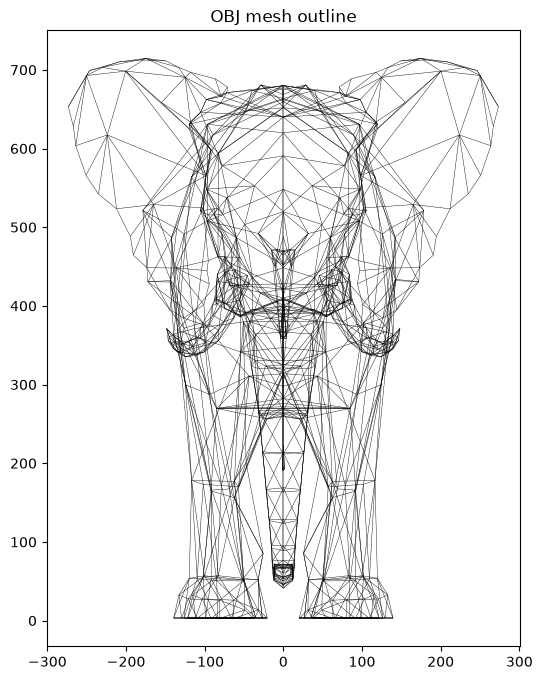

In [7]:
g = ds.plot_outline()
g.ax.set_title("OBJ mesh outline")


The wireframe reveals the elephant's silhouette as a dense triangular mesh — the first example in this set with enough cells to look like a real surface rather than a toy.

## 8. A data map: attach and colour by cell area

These surface formats carry no field data, so there is nothing to colour by yet. We attach a derived **`cell_area`** variable at the face location and plot it — turning the geometry into a proper choropleth.

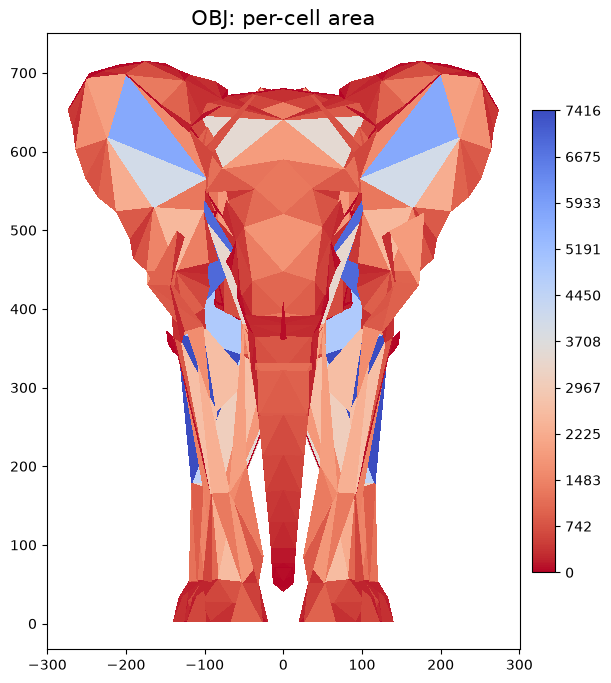

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True,
        title="OBJ: per-cell area")


Shading by `cell_area` exposes the triangulation's density: tightly packed small triangles (dark) where the model needs detail, larger triangles (bright) across flat expanses — the classic signature of an adaptively tessellated 3D asset.

## 9. GIS operations, for free

Because a `UgridDataset` is a first-class pyramids object, a whole GIS toolkit comes along. First, every face as a row in a GeoDataFrame.

In [9]:
gdf = ds.to_geodataframe()
print(gdf.shape, list(gdf.columns))
gdf.head()

(1148, 1) ['geometry']


,geometry
0,"POLYGON ((61.272 446.228, 45.632 438.882, 58.8..."
1,"POLYGON ((45.632 438.882, 43.214 428.401, 58.8..."
2,"POLYGON ((43.214 428.401, 56.434 425.264, 58.8..."
3,"POLYGON ((56.434 425.264, 72.074 432.61, 58.85..."
4,"POLYGON ((72.074 432.61, 74.493 443.092, 58.85..."


1148 polygon rows, one per triangle. This is a substantial vector layer ready for any geopandas workflow.

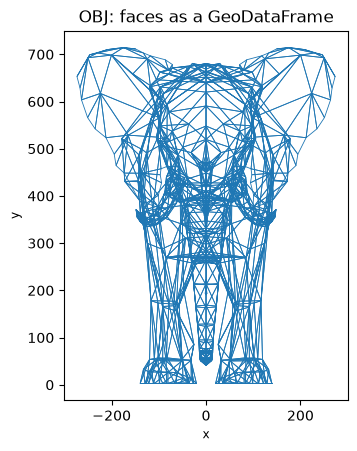

In [10]:
ax = gdf.boundary.plot(color="#1f77b4", linewidth=0.6)
ax.set_title("OBJ: faces as a GeoDataFrame")
ax.set_aspect("equal")


The GeoDataFrame is the gateway to the entire shapely/geopandas ecosystem — spatial joins, buffering, reprojection, export to any OGR vector format — all on the mesh cells.

### Bounding polygon

`bounding_polygon()` returns a single shapely geometry: the dissolved outer footprint of the mesh.

Polygon 225226.7763


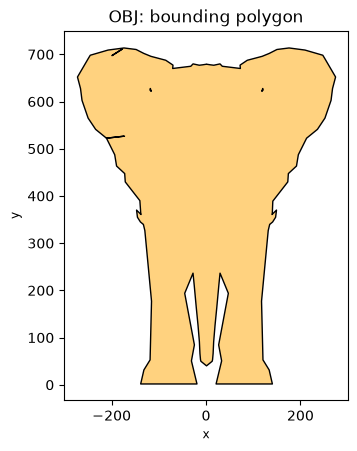

In [11]:
import geopandas as gpd

poly = ds.bounding_polygon()
ax = gpd.GeoSeries([poly]).plot(facecolor="#ffd27f", edgecolor="k")
ax.set_title("OBJ: bounding polygon")
ax.set_aspect("equal")
print(type(poly).__name__, round(poly.area, 4))

The bounding polygon dissolves all 1148 triangles into the single outer silhouette of the elephant in plan view.

### Derived topology and connectivity

A few more derived quantities are a method call away. `circumcenters()` is defined only for triangular meshes; `exterior_edges()` indexes the boundary edges; `connected_components()` labels disjoint pieces; `sparse_adjacency()` is the face-to-face graph as a sparse matrix.

In [12]:
try:
    cc = np.asarray(ds.circumcenters())
    circ = f"{cc.shape} array"
except ValueError as e:
    circ = f"skipped ({e})"
ext = np.asarray(ds.exterior_edges())
comp = np.asarray(ds.connected_components())
adj = ds.sparse_adjacency()
pd.Series({
    "circumcenters": circ,
    "n_boundary_edges": int(ext.size),
    "n_connected_components": int(np.unique(comp).size),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}).to_frame("value")

,value
circumcenters,"(1148, 2) array"
n_boundary_edges,86
n_connected_components,5
adjacency_shape,"(1148, 1148)"
adjacency_nnz,3346


Circumcenters are defined (triangular mesh) and number one per face. The boundary-edge count traces the model's open edges, and `connected_components()` finds **several disjoint pieces** — the model is built from more than one surface patch, which the component count reveals.

### Cropping to a bounding box

`crop(bbox=...)` keeps the faces that fall within (or touch) a rectangle, returning a new `UgridDataset`. Here we crop to the left portion of the extent and redraw it.

faces: 1148 -> 819


Text(0.5, 1.0, 'OBJ: cropped to left 60%')

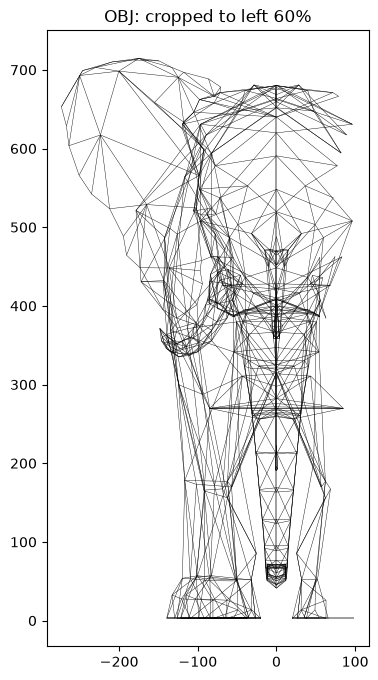

In [13]:
xmin, ymin, xmax, ymax = ds.bounds
bbox = (xmin, ymin, xmin + 0.6 * (xmax - xmin), ymax)
cropped = ds.crop(bbox=bbox)
print(f"faces: {ds.n_face} -> {cropped.n_face}")
gc = cropped.plot_outline()
gc.ax.set_title("OBJ: cropped to left 60%")


Cropping to the left 60% of the extent keeps roughly the corresponding fraction of the triangles and redraws just that slice of the elephant — a real spatial subset, not a trivial one.

### Round-tripping and the xarray view

`to_file(..., driver=...)` writes the mesh back out in any writable driver (here the solver-neutral 2DM), and `to_xarray()` exposes the whole dataset as an `xarray.Dataset` for NetCDF-style analysis.

In [14]:
import tempfile

out = Path(tempfile.gettempdir()) / "roundtrip.2dm"
ds.to_file(out, driver="2dm")
xds = ds.to_xarray()
print("wrote", out.name, "bytes:", out.stat().st_size)
print(xds.dims)

wrote roundtrip.2dm bytes: 50247
FrozenMappingWarningOnValuesAccess({'mesh2d_scalar': 1, 'mesh2d_nNodes': 623, 'mesh2d_nFaces': 1148, 'mesh2d_nMaxFaceNodes': 3})


The mesh survives the round-trip to a different format, and `to_xarray()` hands us a familiar labelled-array object — proof that a format-specific reader produces a fully generic, interoperable dataset.

## 10. What we skip here, and why

- **`to_crs(...)`** needs a source CRS to reproject from, but OBJ files carry no georeferencing (`crs=None`), so there is nothing to reproject. Attach a CRS first if the coordinates are known to be in a specific projection.
- **`rasterize_like(...)` / `regrid(...)`** require a *reference grid* (a raster or target mesh) to sample onto; with only this standalone mesh in hand there is no target, so they are out of scope for this tutorial.

## Takeaway

A substantial Wavefront OBJ model reads into a `UgridDataset` like any other mesh, its 1-based faces renumbered and its winding normalised. Because it is a real surface with over a thousand cells, it shows what the shared pyramids toolkit is actually for: meaningful area maps, a real vector layer, multiple connected components, and genuine spatial cropping — all from a format whose reader only ever parsed `v` and `f` lines.